# Taller 06 — Generación de texto y traducción seq2seq

**Curso:** Procesamiento de Lenguaje Natural — Pontificia Universidad Javeriana
**Autores:** David Moreno · Dierick Brochero
**Repositorio:** https://github.com/davidm094/NLP_JAVE_TALLER06_202601

Adaptación del notebook de clase (*Deep Learning with Python*, 3a ed., cap. 15):

1. **Generación de texto:** modelo de lenguaje por caracteres (GRU) entrenado con *Rebelión en la granja*
   (George Orwell, 1945; trad. de Marcial Souto), elegido por el grupo porque David Moreno lo leyó.
2. **Traducción español → inglés:** seq2seq con GRU (codificador bidireccional) sobre *Combined Data es-ES*,
   evaluado con **BLEU**, **ROUGE** y **F1**.

El código está en `src/`. Con `ENTRENAR = False` el notebook carga los modelos de `results/` **si existen** y recalcula
generaciones y métricas; si no existen, los entrena. En un clon del repositorio (Colab) el modelo de caracteres sí está
(`results/generacion_gru512.keras`), pero el seq2seq (351 MB) no cabe en GitHub y **se reentrena**: sus métricas pueden variar
un poco respecto al reporte. Con `ENTRENAR = True` se reentrenan ambos. Las celdas que calculan métricas sobrescriben los
archivos de `results/` con la corrida actual.

**Sobre el libro:** *Rebelión en la granja* no es de dominio público en Colombia (Orwell murió en 1950 y el plazo es la vida
del autor + 80 años, hasta 2031). Por eso el texto **no está en el repositorio**: hay que subir una copia propia en epub
(celda de carga de la Parte 1). Se usa solo para entrenar el modelo en esta actividad académica.

**En Colab:** *Entorno de ejecución → Cambiar tipo → GPU T4* y ejecutar todo (el seq2seq tarda mucho menos con GPU).
El modelo de caracteres usa una GRU de 512 (el notebook de clase usa 1024) para reproducir el reporte; se cambia con `GEN_OCULTO`.

In [1]:
import os, sys, subprocess
from pathlib import Path
if "google.colab" in sys.modules and Path.cwd().name != "NLP_JAVE_TALLER06_202601":
    if not Path("NLP_JAVE_TALLER06_202601").exists():
        subprocess.run(["git", "clone", "-q", "https://github.com/davidm094/NLP_JAVE_TALLER06_202601"], check=True)
    os.chdir("NLP_JAVE_TALLER06_202601")
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "sacrebleu", "rouge-score"], check=True)
RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ / "src"))
os.environ.setdefault("KERAS_BACKEND", "tensorflow")

'tensorflow'

In [2]:
import json, numpy as np, pandas as pd, keras, tensorflow as tf
from IPython.display import Image, display
import figuras as F
pd.set_option("display.max_colwidth", 120)
GPU = len(tf.config.list_physical_devices("GPU")) > 0
ENTRENAR = False          # True = reentrenar los dos modelos
GEN_OCULTO = 512          # el notebook de clase usa 1024; 512 reproduce el reporte
S2S_OCULTO = 1024
print("Keras", keras.__version__, "| backend", keras.backend.backend(), "| GPU:", GPU)
keras.utils.set_random_seed(42)

I0000 00:00:1793144502.193302    2795 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


I0000 00:00:1793144503.364605    2795 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


Keras 3.15.1 | backend tensorflow | GPU: False


## Parte 1. Modelo de lenguaje por caracteres

### 1.1 Corpus
Del epub se toman solo los capítulos I a X (la novela). Quedan fuera la portada, los créditos, el prólogo de Orwell
(*La libertad de prensa*), el epílogo y las notas. Queda un párrafo por línea.

In [3]:
from libro import cargar_libro, ARCHIVO, PROMPTS
if not ARCHIVO.exists() and "google.colab" in sys.modules:
    from google.colab import files
    print("Suba su copia de Rebelión en la granja en formato epub")
    subido = files.upload()
    if not subido:
        raise RuntimeError("No se subió ningún archivo: vuelva a ejecutar esta celda y elija el epub.")
    ARCHIVO.parent.mkdir(exist_ok=True)
    ARCHIVO.write_bytes(next(iter(subido.values())))

In [4]:
from generacion import preparar, construir_modelo, modelo_generador, generar
texto = cargar_libro()
print(f"{len(texto):,} caracteres, {len(set(texto))} caracteres distintos")
print(texto[:300])  # fragmento corto: el libro tiene derechos vigentes

171,088 caracteres, 83 caracteres distintos
I
El señor Jones, de la Granja Solariega, había echado llave a los gallineros antes de irse a dormir, pero estaba tan borracho que se había olvidado de cerrar las trampillas. Haciendo bailar de un lado a otro el anillo de luz del farol, se tambaleó por el patio, se quitó las botas junto a la puerta 


### 1.2 Datos de entrenamiento
Igual que en el notebook: ventanas no solapadas de 100 caracteres; la etiqueta es la misma ventana corrida un carácter.
A diferencia del notebook, el **último 10 % del libro** se reserva como validación para medir la pérdida en texto no visto
y detener el entrenamiento con *early stopping* (paciencia 3).

In [5]:
tok, d = preparar(texto, largo=100, frac_val=0.10)
print("vocabulario:", len(tok), "| train:", d["x_tr"].shape, "| val:", d["x_va"].shape)
print("x:", repr(tok.decodificar(d["x_tr"][0][:60])))
print("y:", repr(tok.decodificar(d["y_tr"][0][:60])))

vocabulario: 84 | train: (1540, 100) | val: (172, 100)
x: 'I\nEl señor Jones, de la Granja Solariega, había echado llave'
y: '\nEl señor Jones, de la Granja Solariega, había echado llave '


### 1.3 Modelo y entrenamiento

In [6]:
ruta_gen = RAIZ / "results" / f"generacion_gru{GEN_OCULTO}.keras"
modelo = None
if not ENTRENAR and ruta_gen.exists():
    try:
        modelo = keras.models.load_model(ruta_gen)
        print("Modelo cargado de", ruta_gen.name)
    except Exception as e:  # p. ej. otra versión de Keras: se reentrena
        print("No se pudo cargar el modelo guardado (", e, "); se reentrena.")
if modelo is None:
    modelo = construir_modelo(len(tok), oculto=GEN_OCULTO)
    hist = modelo.fit(d["x_tr"], d["y_tr"], batch_size=64, epochs=60,
                      validation_data=(d["x_va"], d["y_va"]),
                      callbacks=[keras.callbacks.EarlyStopping(monitor="val_loss", patience=3,
                                                               restore_best_weights=True)])
    json.dump(hist.history, open(RAIZ / "results" / "historia_generacion.json", "w"))
    modelo.save(ruta_gen)
modelo.summary(line_length=80)
val_loss, val_acc = modelo.evaluate(d["x_va"], d["y_va"], verbose=0)
print(f"Validación: pérdida {val_loss:.3f} nats/carácter | perplejidad {np.exp(val_loss):.2f} | exactitud {val_acc:.3f}")

Modelo cargado de generacion_gru512.keras


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                      ┃ Output Shape             ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ token_ids (InputLayer)            │ (None, 100)              │             0 │
├───────────────────────────────────┼──────────────────────────┼───────────────┤
│ embedding (Embedding)             │ (None, 100, 256)         │        21,504 │
├───────────────────────────────────┼──────────────────────────┼───────────────┤
│ gru (GRU)                         │ (None, 100, 512)         │     1,182,720 │
├───────────────────────────────────┼──────────────────────────┼───────────────┤
│ dropout (Dropout)                 │ (None, 100, 512)         │             0 │
├───────────────────────────────────┼──────────────────────────┼───────────────┤
│ dense (Dense)                     │ (None, 100, 84)          │        43,092 │
└───────────────────────────────────┴──────────────────────────┴───────────────┘

 Total params: 3,741,950 (14.27 MB)

 Trainable params: 1,247,316 (4.76 MB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 2,494,634 (9.52 MB)

Validación: pérdida 1.425 nats/carácter | perplejidad 4.16 | exactitud 0.584


Curvas de la historia de entrenamiento guardada en `results/` (si se reentrenó arriba, son las de esta corrida).

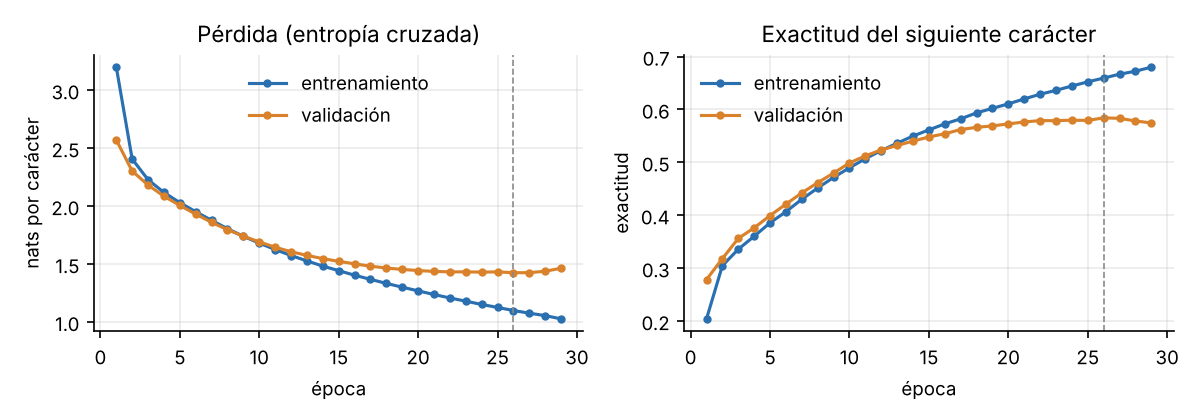

In [7]:
F.fig_curvas_generacion()
display(Image(str(RAIZ / "figs" / "curvas_generacion.png")))

### 1.4 Generación
El notebook de clase usa **argmax** (siempre el carácter más probable), lo que tiende a ciclos repetitivos.
Se compara con **muestreo con temperatura** *T*: se divide el logaritmo de las probabilidades por *T* y se vuelve a
normalizar. *T* < 1 concentra la distribución (texto más conservador); *T* = 1 muestrea del modelo tal cual.

In [8]:
gen = modelo_generador(modelo, len(tok), oculto=GEN_OCULTO)
for k, prompt in enumerate(PROMPTS):     # una semilla por prompt, igual que en el reporte
    for T in [None, 0.5, 0.8, 1.0]:
        print(f"\n=== prompt: {prompt!r} | {'voraz (argmax)' if T is None else f'T = {T}'} ===")
        print(generar(gen, tok, prompt, largo=350, temperatura=T, oculto=GEN_OCULTO, semilla=7 + k))


=== prompt: 'Napoleón' | voraz (argmax) ===


Napoleón era un cerdo de la casa de la casa de la casa de la casa de la casa de la casa de la casa de la casa y los animales de la casa y los animales de la casa y los animales de la casa y los animales de la casa y los animales de la casa y los animales de la casa y los animales de la casa y los animales de la casa y los animales de la casa y los animales

=== prompt: 'Napoleón' | T = 0.5 ===


Napoleón y el abueran en la casa de la casa de la cosecha de la granja, pero el propio se les otra cantar a medida que cabalante de la casa reunidad en la cabaza, y en el aumento con el que causa todo el daño.
Las aves no entendieron las palabras que se opio animal de manera de la casa. Se le actuaba como si los animales de la contenciando con sus probutio

=== prompt: 'Napoleón' | T = 0.8 ===


Napoleón y el avio antes!
¡Que a capar de la apartó de la casa en fila es la mano, el instrumento el trabajo. —Exclamó «Ni tentieron en las lavigas, las gallinas y los animales que a trabajador a la cara. Ahora se hemana de piedra trabajar por la gallina de lo recordar, en un molino de viento no habían bienes. De repente los días que arraban de arroja.
Des

=== prompt: 'Napoleón' | T = 1.0 ===


Napoleón, pero por su cezdíó al actutido a la habían camadadada y Trébol, labatamente, entrendera al capal de la calabra Napoleón, lo les voldó Jones, y que y había reseguado detende sus expulsanes era el lugor de mucho atrepentirado dentro pasa de sus ordenes de actender aunque nunca hubiera situado cómo si una leete dentir tón vuestra los arecar mueztros

=== prompt: '—¡Camaradas' | voraz (argmax) ===


...

—¡Camaradas Morcera de repente hacia el trabajo contrá lado de lo que se les había indenedo en finalentes. Sin deba debe de comité iba a la mucho a los otros.
Una manexaliente y creaina, y camaradas, cuatro hacerse al puertad de los tiempos por dal año sus decía que el hombre Un rebelidad, del año anterinte que solo lo era los animales la parte para realidad.

=== prompt: 'Bola de Nieve' | voraz (argmax) ===


Bola de Nieve y Napoleón era una escalera de la casa de la casa de la casa de la casa de la casa de la casa de la casa de la casa y los animales de la casa y los animales de la casa y los animales de la casa y los animales de la casa y los animales de la casa y los animales de la casa y los animales de la casa y los animales de la casa y los animales de la casa

=== prompt: 'Bola de Nieve' | T = 0.5 ===


Bola de Nieve se los animales de la Granja Animal y el momento no había enterado la primera camarada Napoleón, a pesar de la cabeza de haber visto que te hablaba y que tú te dejabas acariciar la peza de pintura. Los animales se dispersaban.
El tercer domingo después de la cantaría a la casa recibida de piedra la compantar la parte del camarada Napoleón se desab

=== prompt: 'Bola de Nieve' | T = 0.8 ===


Bola de Nieve, tirmpían a vuces partían lo una la Granja Solariel, pero acompañaron con la careza de acuerdo de su alterado de «¡Pueltas y después de la trabajar la concera de que también era debenía la ibudad de Bola de Nieve, que se los suevos la distención. De lugar nada parecía una impresión de la cabaza y los cuatro camaradas, tacho al ahora —dijo Boxeador

=== prompt: 'Bola de Nieve' | T = 1.0 ===


Bola de Nieve. Trébol se apórdó cadó hubo en realizar la granja entre a recordar la vida mucha mitado una beniba muerto con la Rebueta, más terreno estaba arridad de ingruso, y se taberon en reatirás de lo, el rebultad del molino de viento,
cubos humanos y habían síy durante en bolar de perderel sin lentiera que los animales trabajara un lor peridía se servía u


### 1.5 Calidad del texto según la estrategia
Para no juzgar a ojo: 500 caracteres por prompt y estrategia (dos semillas con muestreo). Se mide qué porcentaje de las
palabras existe en el libro, qué fracción de bigramas es distinta (repetición), qué porcentaje de 5-gramas de palabras está
**copiado literalmente del libro** (memorización) y el tramo copiado más largo. Toma unos minutos en CPU.

In [9]:
subprocess.run([sys.executable, str(RAIZ / "src" / "evaluar_generacion.py"), str(GEN_OCULTO)], check=True)
pd.read_csv(RAIZ / "results" / "calidad_generacion.csv").round(2)

I0000 00:00:1793144764.913201    5148 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


I0000 00:00:1793144765.988181    5148 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


{'estrategia': 'argmax', 'palabras': 355, 'pct_palabras_reales': 99.43661971830986, 'bigramas_distintos': 0.11079545454545454, 'pct_5gramas_copiados': 25.364431486880466, 'tramo_copiado_max': 10}


{'estrategia': 'T=0.5', 'palabras': 590, 'pct_palabras_reales': 93.89830508474576, 'bigramas_distintos': 0.8493150684931506, 'pct_5gramas_copiados': 15.547703180212014, 'tramo_copiado_max': 13}


{'estrategia': 'T=0.8', 'palabras': 563, 'pct_palabras_reales': 82.94849023090586, 'bigramas_distintos': 0.9371633752244165, 'pct_5gramas_copiados': 0.5565862708719852, 'tramo_copiado_max': 5}


{'estrategia': 'T=1.0', 'palabras': 539, 'pct_palabras_reales': 70.68645640074212, 'bigramas_distintos': 0.9699812382739212, 'pct_5gramas_copiados': 0.7766990291262136, 'tramo_copiado_max': 7}


,estrategia,palabras,pct_palabras_reales,bigramas_distintos,pct_5gramas_copiados,tramo_copiado_max
0,argmax,355,99.44,0.11,25.36,10
1,T=0.5,590,93.90,0.85,15.55,13
2,T=0.8,563,82.95,0.94,0.56,5
3,T=1.0,539,70.69,0.97,0.78,7


## Parte 2. Traducción español → inglés (seq2seq)

### 2.1 Datos
*Combined Data es-ES* tiene la columna `statement` (inglés original) y `statement_es_es` (traducción al español).
Pasos de limpieza:

1. normalizar (minúsculas, sin puntuación ni ¿¡; el apóstrofo se borra: *don't → dont*);
2. quedarse con frases cortas: ≤ 20 palabras en español y ≤ 19 en inglés (para que `[start]` + 19 + `[end]` quepa en las
   21 posiciones del notebook). Un seq2seq sin atención comprime toda la frase en un solo vector, y la mediana del dataset
   es de 53 palabras en español y 62 en inglés;
3. quitar pares duplicados;
4. quitar pares cuyo "español" es idéntico al inglés (no están traducidos: hashes, risas, otros idiomas).

Partición aleatoria 70 / 15 / 15 (semilla 42), igual que el notebook.

In [10]:
from traduccion import (cargar_pares, particionar, preparar as preparar_tr, construir_seq2seq,
                        traducir_lote, evaluar)
df, conteo = cargar_pares(RAIZ / "data" / "Combined_Data_es-ES.csv.gz")
print(conteo)
tr, va, te = particionar(df)
v_es, v_en, Dtr, Dva, Dte = preparar_tr(tr, va, te)
print(f"train {len(tr)} | val {len(va)} | test {len(te)} | vocab es {len(v_es)} | vocab en {len(v_en)}")
tr[["es", "en"]].head(8)

{'filas': 53043, 'pares_validos': 52671, 'cortos': 15045, 'sin_duplicados': 14772, 'sin_identicos': 13940}
train 9758 | val 2091 | test 2091 | vocab es 13495 | vocab en 11987


,es,en
0,debería escribir un artículo sobre qué hacer si vuelves a caer en la depresión,i should write an article on what to do if you slip back into depression
1,está viendo algunas de sus viejas cosas en youtube ay los recuerdos,is watching some of his old stuff on youtube ahhh the memories
2,dougiemcfly tommcfly buenos días tipo cómo estáis vosotros sabéis que me frustra que nunca recibo respuesta,dougiemcfly tommcfly good morning guy how are you all you know it s frustrating i never get a reply
3,kingkiwi quiero estar en algún lugar sin lluvia no me gusta mucho aquí hoy,kingkiwi i want to be somewhere with no rain it not very nice here today
4,sí tiene muchos cuartos y mucho espacio,yes it has lots of rooms and lots of space
5,http twitpic com y cf lleno de curry el verdadero indio en mí está saliendo,http twitpic com y cf filled with curry the true indian in me is coming out
6,miedo en el alma herido y magullado mi brazo el tambor conflicto interno dolor,dreadkey i m k o d battered and bruised my arm the tambourine self conflicted pain
7,quot está asombrada por todo lo que ve por tu camino quot,quot is in awe of everything she sees your way quot


### 2.2 Modelo
Arquitectura del notebook: embedding (256) → GRU bidireccional de 1024 unidades (suma de direcciones) como codificador;
su estado final inicializa la GRU del decodificador, que recibe la frase en inglés corrida un paso (*teacher forcing*).
Único cambio: `mask_zero=True` en el embedding del codificador, para que la dirección hacia atrás no empiece leyendo
relleno.

In [11]:
ruta_s2s = RAIZ / "results" / f"seq2seq_gru{S2S_OCULTO}.keras"
s2s = None
if not ENTRENAR and ruta_s2s.exists():
    try:
        s2s = keras.models.load_model(ruta_s2s)
        print("Modelo cargado de", ruta_s2s.name)
    except Exception as e:
        print("No se pudo cargar el modelo guardado (", e, "); se reentrena.")
if s2s is None:
    s2s = construir_seq2seq(len(v_es), len(v_en), oculto=S2S_OCULTO)
    s2s.fit(Dtr[0], Dtr[1], sample_weight=Dtr[2], batch_size=64, epochs=15, validation_data=Dva,
            callbacks=[keras.callbacks.EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True)])
    json.dump(s2s.history.history, open(RAIZ / "results" / "historia_traduccion.json", "w"))
    s2s.save(ruta_s2s)
s2s.summary(line_length=80)

Modelo cargado de seq2seq_gru1024.keras


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)          ┃ Output Shape      ┃     Param # ┃ Connected to       ┃
┡━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━┩
│ spanish (InputLayer)  │ (None, None)      │           0 │ -                  │
├───────────────────────┼───────────────────┼─────────────┼────────────────────┤
│ english (InputLayer)  │ (None, None)      │           0 │ -                  │
├───────────────────────┼───────────────────┼─────────────┼────────────────────┤
│ embedding (Embedding) │ (None, None, 256) │   3,454,720 │ spanish[0][0]      │
├───────────────────────┼───────────────────┼─────────────┼────────────────────┤
│ not_equal (NotEqual)  │ (None, None)      │           0 │ spanish[0][0]      │
├───────────────────────┼───────────────────┼─────────────┼────────────────────┤
│ embedding_1           │ (None, None, 256) │   3,068,672 │ english[0][0]      │
│ (Embedding)           │                   │             │                    │
├───────────────────────┼───────────────────┼─────────────┼────────────────────┤
│ bidirectional         │ (None, 1024)      │   7,876,608 │ embedding[0][0],   │
│ (Bidirectional)       │                   │             │ not_equal[0][0]    │
├───────────────────────┼───────────────────┼─────────────┼────────────────────┤
│ gru_1 (GRU)           │ (None, None,      │   3,938,304 │ embedding_1[0][0], │
│                       │ 1024)             │             │ bidirectional[0][… │
├───────────────────────┼───────────────────┼─────────────┼────────────────────┤
│ dropout (Dropout)     │ (None, None,      │           0 │ gru_1[0][0]        │
│                       │ 1024)             │             │                    │
├───────────────────────┼───────────────────┼─────────────┼────────────────────┤
│ dense (Dense)         │ (None, None,      │  12,286,675 │ dropout[0][0]      │
│                       │ 11987)            │             │                    │
└───────────────────────┴───────────────────┴─────────────┴────────────────────┘

 Total params: 91,874,939 (350.48 MB)

 Trainable params: 30,624,979 (116.83 MB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 61,249,960 (233.65 MB)

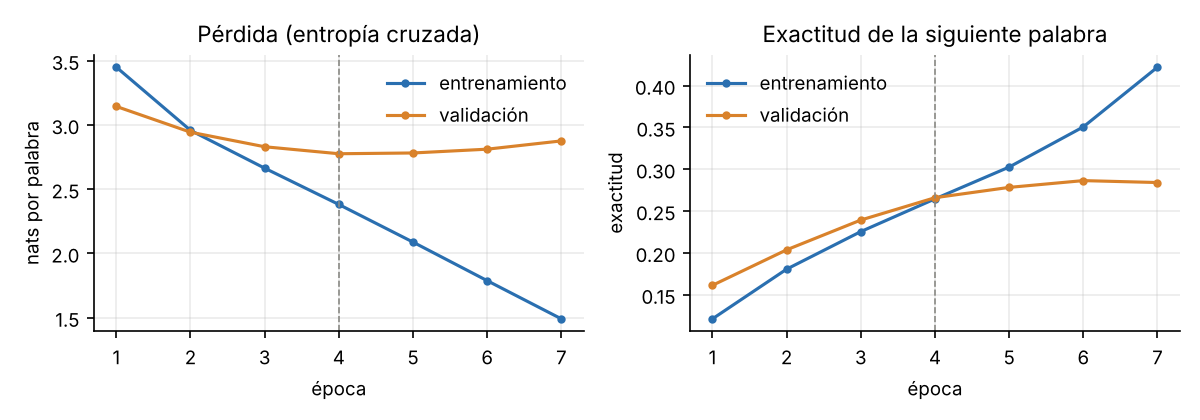

In [12]:
F.fig_curvas_traduccion()
display(Image(str(RAIZ / "figs" / "curvas_traduccion.png")))

### 2.3 Traducción del conjunto de prueba
Decodificación voraz igual a `generate_translation` del notebook, pero en lotes: en el paso *i* se toma el argmax de la
posición *i* y se agrega a la entrada del decodificador hasta producir `[end]` o llegar a 20 palabras.

In [13]:
hip = traducir_lote(s2s, v_es, v_en, te.es.tolist())
ref = te.en.tolist()
muestra = pd.DataFrame({"español": te.es.values, "referencia": ref, "predicción": hip}).sample(12, random_state=3)
muestra

,español,referencia,predicción
1441,estirar estirar,lay down lay down,i am going to be here
908,las relaciones durarán más si amas a un hombre más que a una mujer,relationships will last longer if you love a man more than a woman,where are you going to be a little one of a restaurant
1908,creo que apagar el despertador hoy hará que la vida sea más tranquila eh sabes ®â€ ¨,i think turning off the alarm today will make life calm eh you know ®â€ ¨,i think about the most of the attached of the corner so much to be nervous
85,ni yo,neither did i,i dont like
393,si se ha perdido ya no es lo más guay,if its wasted its no longer the hottest hegeh,if you are the problem but not not
637,quiero vomitar cuando pienso en mí mismo odio mi vida,it literally makes me want to vomit when i think about myself i hate myself,i want to die i am i just want to die i am i am i am i am i
890,buen marketing tío,cool marketing bro,very proud
456,he perdido el móvil tal vez esté en la hierba ha sido muy largo espero que no llueva,lost my phone some where maybe in the grass it just so long hope it doesn t rain,i miss the glass of the band but i dont know what to do it
194,carlyw haha lloré supongo que él sí,carlyw haha i cried i guess he did,buk haha i hope i dont know that
892,jajaja soy paranormal wa está muy bien esta noche,lolzitsmel paranormal wa pretty good tonight,oh im so much


### 2.4 Métricas (implementación propia en `src/metricas.py`)
* **BLEU** de corpus: para n = 1..4 se cuentan los n-gramas de cada predicción, recortados al número de veces que aparecen
  en la referencia; p_n = coincidencias / total en todo el corpus. BLEU = BP · exp(¼ Σ log p_n), con penalización de
  brevedad BP = exp(1 − r/c) si la salida total es más corta que la referencia. Escala 0–100.
* **ROUGE-1 / ROUGE-2**: F de unigramas / bigramas compartidos. **ROUGE-L**: F con la subsecuencia común más larga
  (programación dinámica). Por frase y promediado. Escala 0–100.
* **F1** por palabras: precisión = palabras de la predicción que están en la referencia (contando repeticiones);
  recall = palabras de la referencia que aparecen en la predicción; F1 = media armónica. Por frase y promediado.

Las métricas se calculan sobre el texto normalizado (minúsculas, sin puntuación), que es la forma en que el modelo produce
el inglés. Como línea base se "traduce" copiando la frase en español sin cambios. Las implementaciones propias se validan
contra `sacrebleu` y `rouge-score` al final de esta sección.

In [14]:
from evaluar_traduccion import calcular_y_guardar
t_test = te[["es", "en", "status"]].reset_index(drop=True).assign(prediccion=hip)
res, base, por_largo = calcular_y_guardar(t_test)   # guarda las tablas en results/
cols = ["BLEU", "ROUGE1", "ROUGE2", "ROUGEL", "F1", "Precision", "Recall", "exactas"]
tabla = pd.DataFrame([{k: res[k] for k in cols}, {k: base[k] for k in cols}],
                     index=["seq2seq GRU", "línea base: copiar el español"]).round(2)
print(res["BLEU_detalle"])
tabla

BLEU = 3.32 | precisiones 1-4: 21.9/5.2/1.8/0.7 | BP = 0.955


,BLEU,ROUGE1,ROUGE2,ROUGEL,F1,Precision,Recall,exactas
seq2seq GRU,3.32,21.88,5.73,21.06,21.81,23.29,21.39,0.38
línea base: copiar el español,3.47,10.22,3.23,10.12,10.50,10.61,10.60,0.00


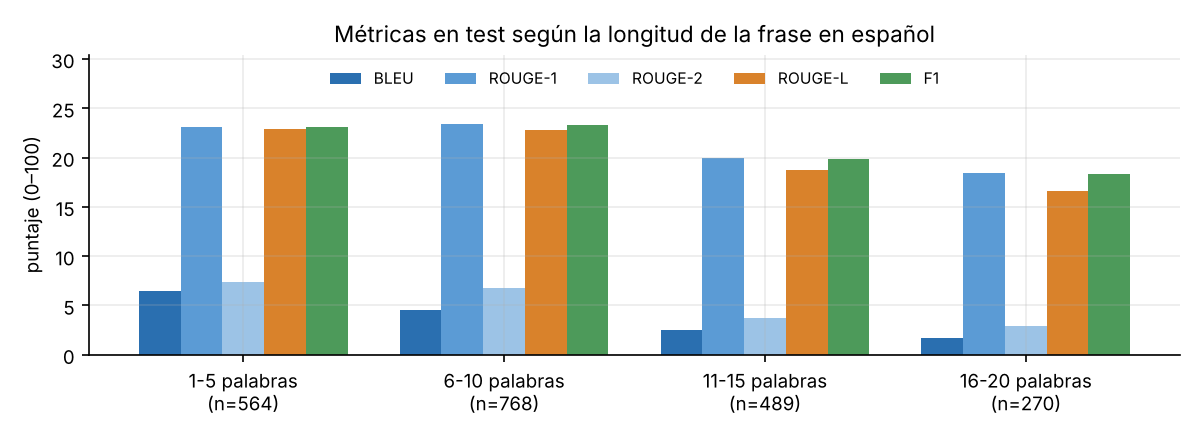

,tramo,n,BLEU,ROUGE1,ROUGE2,ROUGEL,F1
0,1-5,564,6.44,23.12,7.41,22.92,23.06
1,6-10,768,4.58,23.43,6.77,22.75,23.35
2,11-15,489,2.47,19.91,3.73,18.76,19.83
3,16-20,270,1.73,18.46,2.87,16.57,18.38


In [15]:
F.fig_por_largo(); display(Image(str(RAIZ / "figs" / "metricas_por_largo.png")))
por_largo.round(2)

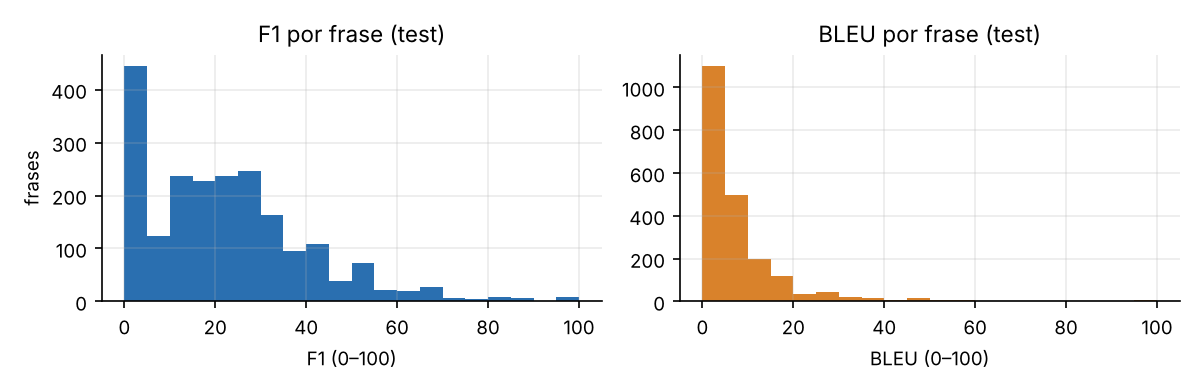

In [16]:
F.fig_distribucion(); display(Image(str(RAIZ / "figs" / "distribucion_frases.png")))

### 2.5 Validación de las métricas propias
Se comparan con las librerías de referencia sobre las mismas predicciones. BLEU propio usa palabras separadas por espacio
como tokens, lo que equivale a `sacrebleu` con `tokenize='none'`; el tokenizador por defecto de sacrebleu (`13a`) separa
algunos símbolos y da un valor ligeramente distinto, que se muestra como referencia.

In [17]:
pd.read_csv(RAIZ / "results" / "validacion_metricas.csv").round(4)

,metrica,propia,libreria,libreria_nombre,max_dif_por_frase,diferencia
0,BLEU (corpus),3.3173,3.3173,sacrebleu.corpus_bleu(tokenize='none'),NaN,-0.0
1,"BLEU (corpus), tokenizador 13a",NaN,3.3140,"sacrebleu.corpus_bleu (por defecto, 13a)",NaN,NaN
2,ROUGE-1 (promedio),21.8813,21.8813,rouge_score.RougeScorer,0.0,0.0
3,ROUGE-2 (promedio),5.7285,5.7285,rouge_score.RougeScorer,0.0,0.0
4,ROUGE-L (promedio),21.0650,21.0650,rouge_score.RougeScorer,0.0,0.0
